# MLR Model — Hourly Energy Consumption Predictor
Trains a Multivariate Linear Regression model on weather parameters.  
After training, use `predict_energy(input_dict)` to get a prediction for any set of weather inputs.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print('Libraries loaded.')

Libraries loaded.


In [3]:

FILE_PATH = '../data/processed/final_training_dataset.csv'

df = pd.read_csv(FILE_PATH)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

print(f'Dataset shape  : {df.shape}')
print(f'Columns        : {df.columns.tolist()}')

Dataset shape  : (2129, 23)
Columns        : ['timestamp', 'energy_kwh.1', 'temp_hi', 'bar', 'dew_in', 'temp_in', 'pt_dew', 'index_thsw', 'index_uv', 'hum_out', 'dose_uv', 'dd_heat', 'temp_low', 'density_in_air', 'rain', 'run_wind', 'emc_in', 'rate_rain', 'out_temp', 'speed_hi', 'speed_wind', 'tx_wind', 'hum_in']


In [4]:
# DEFINE FEATURES AND TARGET
TARGET_COL   = 'energy_kwh.1'
DROP_COLS    = ['timestamp', TARGET_COL]

feature_cols = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col not in DROP_COLS
]

X = df[feature_cols]
y = df[TARGET_COL]

print(f'Target   : {TARGET_COL}')
print(f'Features : {feature_cols}')
print(f'X shape  : {X.shape}  |  y shape : {y.shape}')

Target   : energy_kwh.1
Features : ['temp_hi', 'bar', 'dew_in', 'temp_in', 'pt_dew', 'index_thsw', 'index_uv', 'hum_out', 'dose_uv', 'dd_heat', 'temp_low', 'density_in_air', 'rain', 'run_wind', 'emc_in', 'rate_rain', 'out_temp', 'speed_hi', 'speed_wind', 'tx_wind', 'hum_in']
X shape  : (2129, 21)  |  y shape : (2129,)


In [5]:
# TRAIN-TEST SPLIT  (80 / 20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Train rows : {X_train.shape[0]}')
print(f'Test  rows : {X_test.shape[0]}')

Train rows : 1703
Test  rows : 426


In [6]:
# STANDARDISE FEATURES
# Fit ONLY on training data — then transform both sets with the same scaler.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('Scaling complete.')

Scaling complete.


In [7]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print('Model trained.')

Model trained.


In [8]:
# EVALUATION

y_train_pred = model.predict(X_train_scaled)
y_test_pred  = model.predict(X_test_scaled)

train_r2  = r2_score(y_train, y_train_pred)
test_r2   = r2_score(y_test,  y_test_pred)
test_mae  = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print('=' * 42)
print(f'  R\u00b2   \u2014 Train  : {train_r2:.4f}')
print(f'  R\u00b2   \u2014 Test   : {test_r2:.4f}')
print(f'  MAE  \u2014 Test   : {test_mae:.4f} kWh')
print(f'  RMSE \u2014 Test   : {test_rmse:.4f} kWh')
print('=' * 42)

  R²   — Train  : 0.4923
  R²   — Test   : 0.4454
  MAE  — Test   : 37.4121 kWh
  RMSE — Test   : 51.0849 kWh


In [9]:
# FEATURE COEFFICIENTS
coeff_df = (
    pd.DataFrame({'Feature': feature_cols, 'Coefficient': model.coef_})
    .sort_values('Coefficient', ascending=False)
    .reset_index(drop=True)
)

print(f'Intercept : {model.intercept_:.4f}\n')
print('Feature Coefficients (sorted high \u2192 low):')
print(coeff_df.to_string(index=False))

Intercept : 156.2813

Feature Coefficients (sorted high → low):
       Feature   Coefficient
       temp_hi  6.793061e+01
      temp_low  2.382185e+01
        emc_in  2.065717e+01
    index_thsw  1.749516e+01
       hum_out  1.593499e+01
          rain  1.238057e+01
       dose_uv  1.105620e+01
      out_temp  1.002441e+01
           bar  6.751071e+00
      run_wind  6.401831e+00
      speed_hi  5.945751e+00
       tx_wind  0.000000e+00
       dd_heat -1.172396e-13
        dew_in -1.379599e+00
    speed_wind -3.510757e+00
        pt_dew -3.565305e+00
     rate_rain -6.250335e+00
density_in_air -7.529494e+00
      index_uv -8.143531e+00
        hum_in -3.105908e+01
       temp_in -1.096565e+02


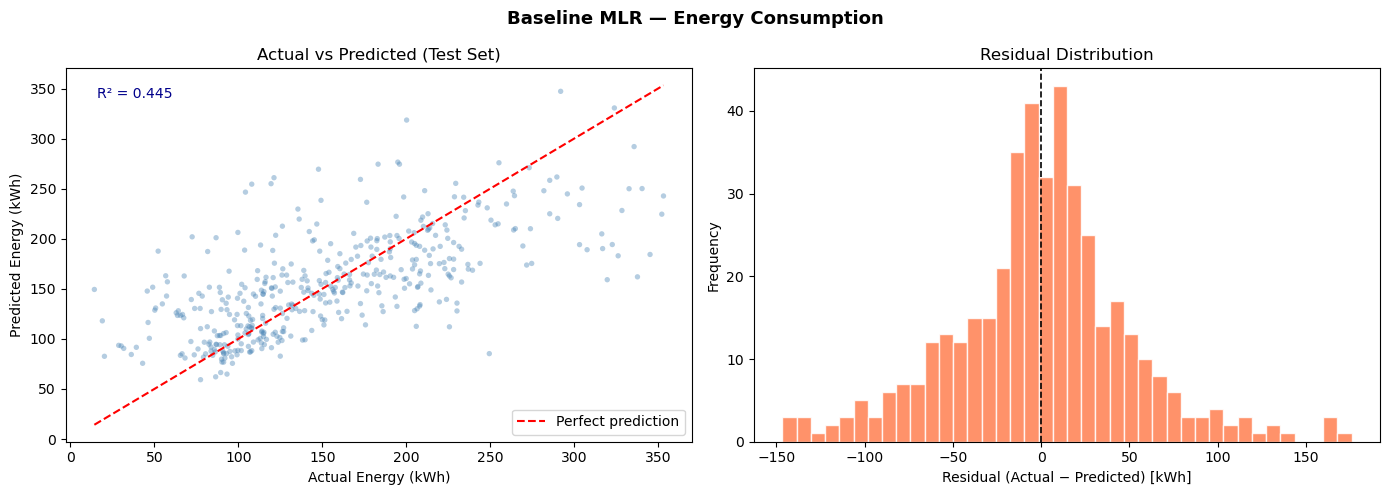

In [10]:
# =============================================================================
# PLOTS  —  Actual vs Predicted  |  Residual Distribution
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Baseline MLR \u2014 Energy Consumption', fontsize=13, fontweight='bold')

# Plot 1 — Actual vs Predicted
ax1 = axes[0]
ax1.scatter(y_test, y_test_pred, alpha=0.4, s=15, color='steelblue', edgecolors='none')
lim = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
ax1.plot(lim, lim, 'r--', linewidth=1.5, label='Perfect prediction')
ax1.set_xlabel('Actual Energy (kWh)')
ax1.set_ylabel('Predicted Energy (kWh)')
ax1.set_title('Actual vs Predicted (Test Set)')
ax1.annotate(f'R\u00b2 = {test_r2:.3f}', xy=(0.05, 0.92), xycoords='axes fraction',
             fontsize=10, color='darkblue')
ax1.legend()

# Plot 2 — Residuals
residuals = y_test.values - y_test_pred
ax2 = axes[1]
ax2.hist(residuals, bins=40, color='coral', edgecolor='white', alpha=0.85)
ax2.axvline(0, color='black', linestyle='--', linewidth=1.2)
ax2.set_xlabel('Residual (Actual \u2212 Predicted) [kWh]')
ax2.set_ylabel('Frequency')
ax2.set_title('Residual Distribution')

plt.tight_layout()
plt.savefig('../outputs/figures/mlr_plots.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# =============================================================================
# PREDICTION FUNCTION
# A user provides their local weather parameters and gets back predicted energy.
# =============================================================================

def predict_energy(input_dict: dict) -> float:
    """
    Predict hourly energy consumption from user-supplied weather parameters.

    Parameters
    ----------
    input_dict : dict
        All 21 weather feature values. Keys must match exactly:
        temp_hi, bar, dew_in, temp_in, pt_dew, index_thsw, index_uv,
        hum_out, dose_uv, dd_heat, temp_low, density_in_air, rain,
        run_wind, emc_in, rate_rain, out_temp, speed_hi, speed_wind,
        tx_wind, hum_in

    Returns
    -------
    float
        Predicted energy consumption in kWh.

    Example
    -------
    >>> predict_energy({
    ...     'temp_hi': 30.4, 'bar': 29.8, 'dew_in': 21.4, 'temp_in': 25.7,
    ...     'pt_dew': 26.0, 'index_thsw': 43.6, 'index_uv': 3.7,
    ...     'hum_out': 76.0, 'dose_uv': 0.4, 'dd_heat': 0.0, 'temp_low': 30.7,
    ...     'density_in_air': 0.0716, 'rain': 0.0, 'run_wind': 2.7,
    ...     'emc_in': 15.0, 'rate_rain': 0.0, 'out_temp': 30.7,
    ...     'speed_hi': 19.3, 'speed_wind': 10.9, 'tx_wind': 1.0, 'hum_in': 77.3
    ... })
    """
    input_df     = pd.DataFrame([input_dict])[feature_cols]   # enforce column order
    input_scaled = scaler.transform(input_df)                 # same scaler as training
    prediction   = model.predict(input_scaled)[0]
    return round(float(prediction), 4)


# ── QUICK TEST — use the first row of the test set ────────────────────────────
sample_input    = {col: float(X_test.iloc[0][col]) for col in feature_cols}
predicted_value = predict_energy(sample_input)
actual_value    = float(y_test.iloc[0])

print('Sample weather input :')
for k, v in sample_input.items():
    print(f'  {k:<20} : {v}')
print(f'\nPredicted energy : {predicted_value} kWh')
print(f'Actual energy    : {actual_value} kWh')
print(f'Absolute error   : {abs(predicted_value - actual_value):.4f} kWh')

Sample weather input :
  temp_hi              : 25.825
  bar                  : 29.87375
  dew_in               : 23.2
  temp_in              : 28.35
  pt_dew               : 24.65
  index_thsw           : 37.25
  index_uv             : 1.725
  hum_out              : 94.0
  dose_uv              : 0.185
  dd_heat              : 0.0
  temp_low             : 25.5
  density_in_air       : 0.070975
  rain                 : 0.0
  run_wind             : 2.2125
  emc_in               : 14.09
  rate_rain            : 0.0
  out_temp             : 25.675
  speed_hi             : 17.3
  speed_wind           : 8.85
  tx_wind              : 1.0
  hum_in               : 74.0

Predicted energy : 151.5352 kWh
Actual energy    : 206.75 kWh
Absolute error   : 55.2148 kWh
